# TF-IDF Logistic Regression

This notebook trains and evaluates Logistic Regression using the project's **shared fitted TF-IDF vectorizer**.

Feature extraction is intentionally separated from model training. Run `tfidf_feature_extraction.ipynb` first whenever the shared vectorizer needs to be regenerated.

## 1. Imports and project paths

In [3]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

PROJECT_ROOT = Path("../..")

DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"

MODELS_DIR = PROJECT_ROOT / "models"
TFIDF_MODEL_DIR = MODELS_DIR / "tfidf"

import matplotlib.pyplot as plt

from scipy.sparse import vstack
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
)

## 2. Load the data and shared TF-IDF representation

The vectorizer is loaded from disk and only `.transform()` is used here. This notebook does not fit or redefine TF-IDF.

In [4]:
train = pd.read_csv(PROCESSED_DIR / "train.csv")
validation = pd.read_csv(PROCESSED_DIR / "validation.csv")
test = pd.read_csv(PROCESSED_DIR / "test.csv")

vectorizer = joblib.load(
    TFIDF_MODEL_DIR / "tfidf_vectorizer.joblib"
)

X_train = vectorizer.transform(train["text"].astype(str))
X_validation = vectorizer.transform(validation["text"].astype(str))
X_test = vectorizer.transform(test["text"].astype(str))

y_train = train["target"].astype(int)
y_validation = validation["target"].astype(int)
y_test = test["target"].astype(int)

print("Train:", X_train.shape)
print("Validation:", X_validation.shape)
print("Test:", X_test.shape)

Train: (58823, 100000)
Validation: (12611, 100000)
Test: (12632, 100000)


## 3. Tune Logistic Regression on the validation set

We tune the regularization parameter `C` using validation macro-F1, with accuracy as the secondary sorting metric.

In [5]:
C_VALUES = [0.1, 1.0, 4.0, 10.0, 20.0, 50.0, 100.0]
RANDOM_STATE = 42

validation_rows = []

for c_value in C_VALUES:
    candidate = LogisticRegression(
        C=c_value,
        class_weight="balanced",
        solver="lbfgs",
        max_iter=1000,
        random_state=RANDOM_STATE,
    )

    candidate.fit(X_train, y_train)

    predictions = candidate.predict(X_validation)

    validation_rows.append({
        "C": c_value,
        "accuracy": accuracy_score(
            y_validation,
            predictions,
        ),
        "macro_f1": f1_score(
            y_validation,
            predictions,
            average="macro",
        ),
    })

validation_results = pd.DataFrame(validation_rows)

print(
    validation_results
    .round(4)
    .to_string(index=False)
)

best_c = float(
    validation_results
    .sort_values(
        ["macro_f1", "accuracy"],
        ascending=False,
    )
    .iloc[0]["C"]
)

print(
    f"Selected C={best_c:g} "
    "using validation macro-F1"
)

    C  accuracy  macro_f1
  0.1    0.9592    0.9532
  1.0    0.9802    0.9772
  4.0    0.9854    0.9832
 10.0    0.9869    0.9849
 20.0    0.9871    0.9851
 50.0    0.9878    0.9859
100.0    0.9879    0.9861
Selected C=100 using validation macro-F1


## 4. Train the final classifier

After selecting `C`, we add the validation examples to the classifier's training data.

The **feature extractor is not refit**. Validation text remains represented in the same TF-IDF vocabulary learned from the original training split, keeping the feature space identical across all TF-IDF models.

In [6]:
X_train_validation = vstack(
    [X_train, X_validation]
)

y_train_validation = pd.concat(
    [y_train, y_validation],
    ignore_index=True,
)

model = LogisticRegression(
    C=best_c,
    class_weight="balanced",
    solver="lbfgs",
    max_iter=1000,
    random_state=RANDOM_STATE,
)

model.fit(
    X_train_validation,
    y_train_validation,
)

test_predictions = model.predict(X_test)

## 5. Evaluate on the held-out test set

Majority-class test accuracy: 0.6791
Accuracy:        0.9869
Macro precision: 0.9849
Macro recall:    0.9849
Macro F1:        0.9849

Per-class metrics:
              precision    recall  f1-score   support

       human       0.99      0.99      0.99      8579
     ChatGPT       0.98      0.98      0.98      4053

    accuracy                           0.99     12632
   macro avg       0.98      0.98      0.98     12632
weighted avg       0.99      0.99      0.99     12632



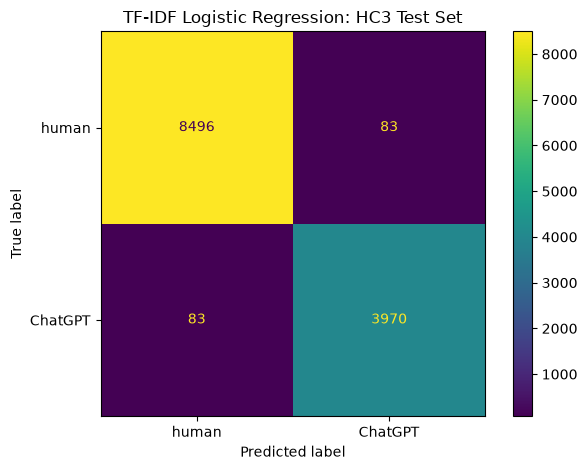

In [7]:
majority_prediction = int(
    y_train_validation.mode().iloc[0]
)

print(
    "Majority-class test accuracy:",
    f"{accuracy_score(y_test, np.full(len(y_test), majority_prediction)):.4f}",
)

print(
    f"Accuracy:        "
    f"{accuracy_score(y_test, test_predictions):.4f}"
)
print(
    f"Macro precision: "
    f"{precision_score(y_test, test_predictions, average='macro', zero_division=0):.4f}"
)
print(
    f"Macro recall:    "
    f"{recall_score(y_test, test_predictions, average='macro', zero_division=0):.4f}"
)
print(
    f"Macro F1:        "
    f"{f1_score(y_test, test_predictions, average='macro', zero_division=0):.4f}"
)

print(
    "\nPer-class metrics:\n"
    + classification_report(
        y_test,
        test_predictions,
        labels=[0, 1],
        target_names=["human", "ChatGPT"],
        zero_division=0,
    )
)

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1],
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["human", "ChatGPT"],
).plot(values_format="d")

plt.title("TF-IDF Logistic Regression: HC3 Test Set")
plt.tight_layout()
plt.show()

## 6. Review performance by HC3 source and inspect influential TF-IDF terms

In [9]:
test_results = test[
    ["id", "source", "text", "target"]
].copy()

test_results["prediction"] = test_predictions

source_rows = []

for source, group in test_results.groupby(
    "source",
    sort=True,
):
    source_rows.append({
        "source": source,
        "n_answers": len(group),
        "accuracy": accuracy_score(
            group["target"],
            group["prediction"],
        ),
        "macro_f1": f1_score(
            group["target"],
            group["prediction"],
            average="macro",
            zero_division=0,
        ),
    })

print(
    pd.DataFrame(source_rows)
    .round(4)
    .to_string(index=False)
)

terms = np.asarray(
    vectorizer.get_feature_names_out()
)

weights = model.coef_[0]

print("\nTop terms associated with ChatGPT:")
print(
    pd.DataFrame({
        "term": terms[np.argsort(weights)[-15:][::-1]],
        "weight": np.sort(weights)[-15:][::-1],
    }).to_string(index=False)
)

print("\nTop terms associated with human answers:")
print(
    pd.DataFrame({
        "term": terms[np.argsort(weights)[:15]],
        "weight": np.sort(weights)[:15],
    }).to_string(index=False)
)

     source  n_answers  accuracy  macro_f1
    finance       1283    0.9844    0.9843
   medicine        388    0.9974    0.9974
    open_qa        710    0.9380    0.9210
reddit_eli5       9997    0.9922    0.9896
  wiki_csai        254    0.9094    0.9094

Top terms associated with ChatGPT:
        term    weight
important to 29.878983
         and 28.867435
   including 27.257233
   important 25.279358
        help 22.152515
         don 21.262999
        sure 21.125797
  example if 20.863575
          or 20.641363
it important 20.489904
   does that 20.298340
    have any 19.959757
       might 19.064623
       helps 19.011822
  means that 18.740498

Top terms associated with human answers:
     term     weight
    url_0 -39.631145
      etc -28.614286
       my -20.955400
       ca -20.833723
     only -20.722816
basically -20.458475
       do -19.842638
      you -18.122061
     most -17.009211
  can not -16.237307
   pretty -16.209526
     thus -15.609160
    those -15.565615
  

## 7. Save the trained classifier

The TF-IDF vectorizer is stored separately as `tfidf_vectorizer.joblib`. This file contains only the Logistic Regression classifier and its model-specific configuration.

In [10]:
model_path = (
    TFIDF_MODEL_DIR
    / "logistic_regression.joblib"
)

joblib.dump(
    {
        "classifier": model,
        "config": {
            "C": best_c,
            "class_weight": "balanced",
            "solver": "lbfgs",
            "max_iter": 1000,
            "random_state": RANDOM_STATE,
            "vectorizer": "tfidf_vectorizer.joblib",
        },
    },
    model_path,
)

print(f"Saved Logistic Regression model to {model_path}")

Saved Logistic Regression model to ../../models/tfidf/logistic_regression.joblib
